In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
# 1. Read dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
# 2. Select numerical sales columns
X = df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]
# Handle missing values
X = X.fillna(X.median())
# 3. Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

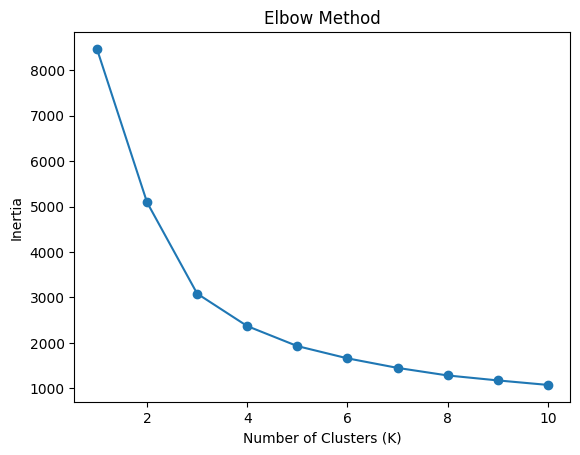

In [4]:
# 4. Elbow Method
inertia = []
for k in range(1, 11):
    model = KMeans(
        n_clusters=k, random_state=42, n_init=10
)
    model.fit(X_scaled)
    inertia.append(model.inertia_)
# Plot elbow curve
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [5]:
# 5. Apply K-Means
k = 3  # Change according to the elbow plot
model = KMeans(
    n_clusters=k, random_state=42, n_init=10
)
df["Cluster"] = model.fit_predict(X_scaled)

In [6]:
 # Display results
print("\nSales data with clusters:")
print(df[[
    "QUANTITYORDERED", "PRICEEACH", "SALES", "Cluster"
]].head(10))
print("\nNumber of records in each cluster:")
print(df["Cluster"].value_counts().sort_index())


Sales data with clusters:
   QUANTITYORDERED  PRICEEACH    SALES  Cluster
0               30      95.70  2871.00        2
1               34      81.35  2765.90        2
2               41      94.74  3884.34        1
3               45      83.26  3746.70        1
4               49     100.00  5205.27        1
5               36      96.66  3479.76        2
6               29      86.13  2497.77        2
7               48     100.00  5512.32        1
8               22      98.57  2168.54        2
9               41     100.00  4708.44        1

Number of records in each cluster:
Cluster
0     881
1     907
2    1035
Name: count, dtype: int64
